In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report

In [ ]:
real_dir = r"C:\Users\Lenovo\Downloads\05_real_and_fake_face-20261022T160649Z-1-001\05_real_and_fake_face\training_real"
fake_dir = r"C:\Users\Lenovo\Downloads\05_real_and_fake_face-20261022T160649Z-1-001\05_real_and_fake_face\training_fake"

In [ ]:
# 3. Create empty lists
X = []
y = []

In [ ]:
for file in os.listdir(real_dir):
    img = Image.open(os.path.join(real_dir, file)).convert("RGB")
    img = img.resize((32, 32))
    X.append(np.array(img).flatten())
    y.append(0)

In [ ]:
for file in os.listdir(fake_dir):
    img = Image.open(os.path.join(fake_dir, file)).convert("RGB")
    img = img.resize((32, 32))
    X.append(np.array(img).flatten())
    y.append(1)

In [ ]:
# 6. Convert lists to arrays
X = np.array(X) / 255.0
y = np.array(y)

print("Total images:", len(X))
print("Real images:", np.sum(y == 0))
print("Fake images:", np.sum(y == 1))

Total images: 2043
Real images: 1081
Fake images: 962


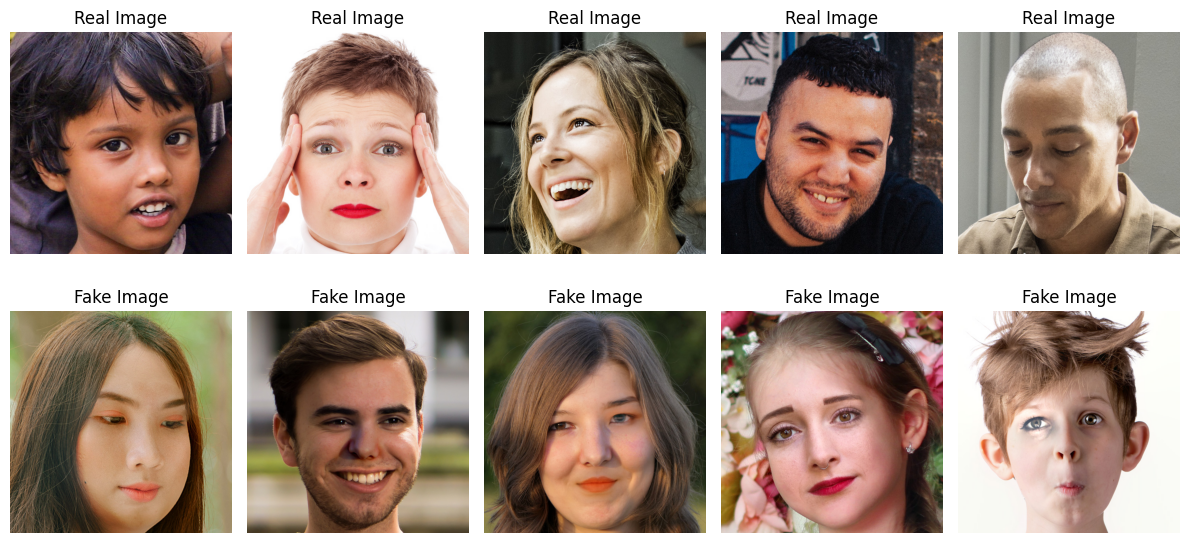

In [ ]:
real_images = os.listdir(real_dir)[:5]
fake_images = os.listdir(fake_dir)[:5]

plt.figure(figsize=(12, 6))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(Image.open(os.path.join(real_dir, real_images[i])))
    plt.title("Real Image")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(Image.open(os.path.join(fake_dir, fake_images[i])))
    plt.title("Fake Image")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
model = SVC(kernel="rbf", C=10, gamma="scale")

model.fit(X_train_scaled, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [ ]:
y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("HOG + SVM Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Real", "Fake"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

HOG + SVM Accuracy: 56.48 %

Classification Report:
              precision    recall  f1-score   support

        Real       0.58      0.62      0.60       216
        Fake       0.54      0.51      0.52       193

    accuracy                           0.56       409
   macro avg       0.56      0.56      0.56       409
weighted avg       0.56      0.56      0.56       409


Confusion Matrix:
[[133  83]
 [ 95  98]]


In [ ]:
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

Accuracy: 56.48 %


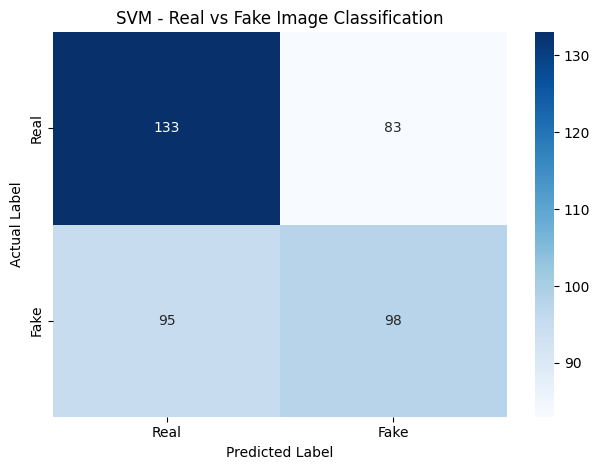

In [ ]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Real", "Fake"],
    yticklabels=["Real", "Fake"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SVM - Real vs Fake Image Classification")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

In [ ]:
# 12. Test one image
path = input("Enter image path: ")

img = Image.open(path).convert("RGB").resize((32, 32))
img = np.array(img).flatten().reshape(1, -1) / 255.0

prediction = model.predict(img)[0]

if prediction == 0:
    print("Real Image")
else:
    print("AI-Generated (Fake) Image")

Enter image path:  Original.jpg


Real Image
